# CM2604 Machine Learning — Telco Customer Churn
**Purpose:** A reproducible workflow for the Part 01 individual coursework.

This notebook covers:
1. Load and inspect the Telco Customer Churn dataset
2. Clean and prepare the data
3. Exploratory Data Analysis (EDA)
4. Train/tune KNN, Logistic Regression and Random Forest
5. Compare models using appropriate classification metrics
6. Save tables and figures for the report
7. Discuss ethical and post-deployment considerations

**Important:** Run every cell in order. Do not invent or copy example results into the report. The numerical results in your report must come from your own successful run of this notebook and the dataset you used.

## 0. Set up the environment

This is designed to run in Google Colab or a local Jupyter notebook. In Colab, run the next cell, then upload the CSV when prompted. If the dataset is already in the current folder, the notebook will use it automatically.

Use the public *Telco Customer Churn* dataset specified in the coursework. Keep a note of the exact source URL, download date, and dataset version for your report.

In [6]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Load the dataset

The original dataset commonly uses the column names `customerID`, `TotalCharges`, and `Churn`. If your downloaded file has a different name, upload it here. The notebook checks for a CSV in the working directory first.

In [7]:
csv_candidates = [f for f in os.listdir(".") if f.lower().endswith(".csv") and "telco" in f.lower()]

if csv_candidates:
    csv_path = csv_candidates[0]
    print(f"Using file: {csv_path}")
    df = pd.read_csv(csv_path)
else:
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_files:
            raise ValueError("No CSV file was uploaded. Upload the Telco Customer Churn CSV and rerun this cell.")
        csv_path = csv_files[0]
        df = pd.read_csv(csv_path)
        print(f"Uploaded and loaded: {csv_path}")
    except ImportError:
        raise FileNotFoundError("Place the Telco Customer Churn CSV in the notebook folder, then rerun this cell.")

print("Dataset shape:", df.shape)
display(df.head())

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn.csv
Uploaded and loaded: WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [23]:
print("Column names:")
print(df.columns.tolist())
print("\nData types and non-null counts:")
df.info()
print("\nDuplicate rows:", df.duplicated().sum())

Column names:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
Index: 7021 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7021 non-null   object 
 1   SeniorCitizen     7021 non-null   int64  
 2   Partner           7021 non-null   object 
 3   Dependents        7021 non-null   object 
 4   tenure            7021 non-null   int64  
 5   PhoneService      7021 non-null   object 
 6   MultipleLines     7021 non-null   object 
 7   InternetService   7021 non-null   object 
 8   OnlineSecurity    7021 non-null   object 
 9   OnlineBackup      7

## 2. Data preparation and quality checks

The target is `Churn`. The identifier `customerID` is removed because it identifies a customer rather than providing a meaningful generalizable behaviour signal. `TotalCharges` can contain blank strings; these are converted to missing numeric values. Missing feature values are imputed inside the modelling pipeline, so the imputation values are learned from each training fold rather than from the full dataset.

If the expected target or columns are absent, check that you uploaded the correct dataset version.

In [9]:
# Normalize column labels and convert common blank representations to missing values.
df.columns = [str(c).strip() for c in df.columns]
df = df.replace(r"^\s*$", np.nan, regex=True)

if "Churn" not in df.columns:
    raise ValueError("Expected a 'Churn' target column. Please check the dataset version.")

# Convert TotalCharges when present; in the standard dataset, some values are blank.
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Standard dataset target values are Yes/No. Convert them to 1/0.
target_values = set(df["Churn"].dropna().astype(str).str.strip().unique())
if target_values.issubset({"Yes", "No"}):
    df["Churn"] = df["Churn"].astype(str).str.strip().map({"No": 0, "Yes": 1})
else:
    df["Churn"] = pd.to_numeric(df["Churn"], errors="coerce")

df = df.dropna(subset=["Churn"]).copy()
df["Churn"] = df["Churn"].astype(int)

# Remove customer identifier if present.
if "customerID" in df.columns:
    df = df.drop(columns=["customerID"])

# Remove exact duplicate rows, if any, and report how many were removed.
before = len(df)
df = df.drop_duplicates().copy()
print("Exact duplicate rows removed:", before - len(df))
print("Shape after basic cleaning:", df.shape)
print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("Target distribution (0 = No churn, 1 = Churn):")
display(df["Churn"].value_counts().rename(index={0:"No churn (0)", 1:"Churn (1)"}).to_frame("count"))

Exact duplicate rows removed: 22
Shape after basic cleaning: (7021, 20)
Missing values by column:


,missing_count
TotalCharges,11
gender,0
Partner,0
SeniorCitizen,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0
OnlineBackup,0


Target distribution (0 = No churn, 1 = Churn):


,count
Churn,
No churn (0),5164
Churn (1),1857


## 3. Exploratory Data Analysis (EDA)

Use the plots and tables as evidence for the report. Describe patterns actually visible in your output; do not claim that a relationship is causal. Numeric group summaries are descriptive and do not prove that a feature causes churn.

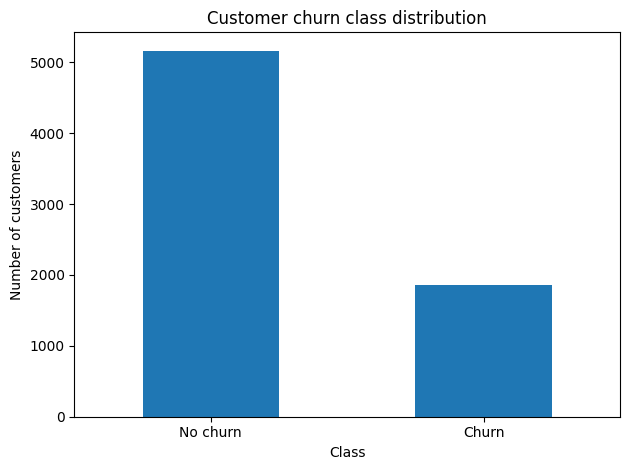

Churn rate (%): 26.45


In [10]:
# Target class distribution
target_counts = df["Churn"].map({0:"No churn", 1:"Churn"}).value_counts()
ax = target_counts.plot(kind="bar", rot=0)
ax.set_title("Customer churn class distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.show()

print("Churn rate (%):", round(df["Churn"].mean() * 100, 2))

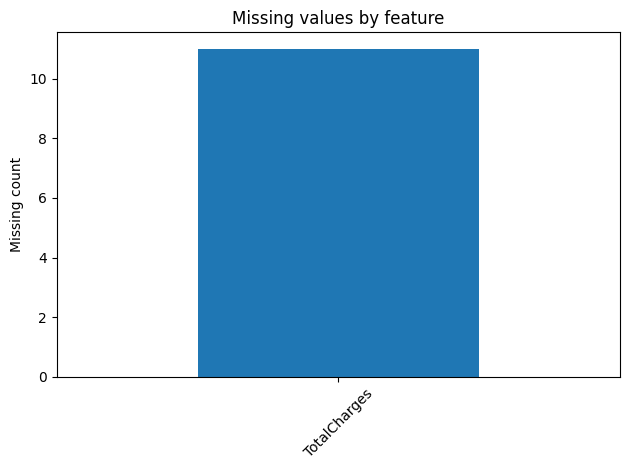

In [11]:
# Missingness after basic conversion
missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
if len(missing):
    ax = missing.plot(kind="bar", rot=45)
    ax.set_title("Missing values by feature")
    ax.set_ylabel("Missing count")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values remain in the current dataframe.")

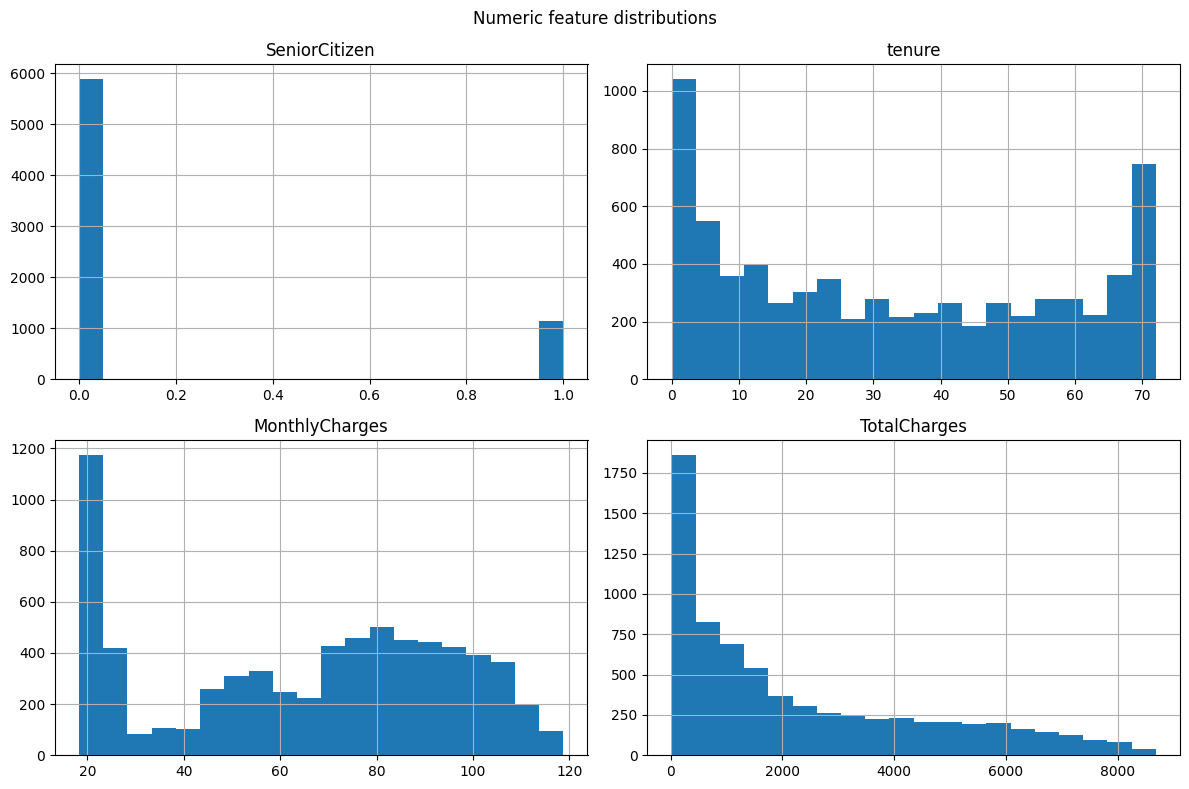

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
Churn,,,,
No churn,0.13,37.64,61.34,2560.26
Churn,0.26,18.09,74.60,1541.38


In [12]:
# Numeric feature distributions and churn-group summaries
numeric_cols = df.drop(columns=["Churn"]).select_dtypes(include=np.number).columns.tolist()
if numeric_cols:
    df[numeric_cols].hist(figsize=(12, 8), bins=20)
    plt.suptitle("Numeric feature distributions")
    plt.tight_layout()
    plt.show()
    display(df.groupby("Churn")[numeric_cols].mean().rename(index={0:"No churn",1:"Churn"}).round(2))
else:
    print("No numeric feature columns found.")

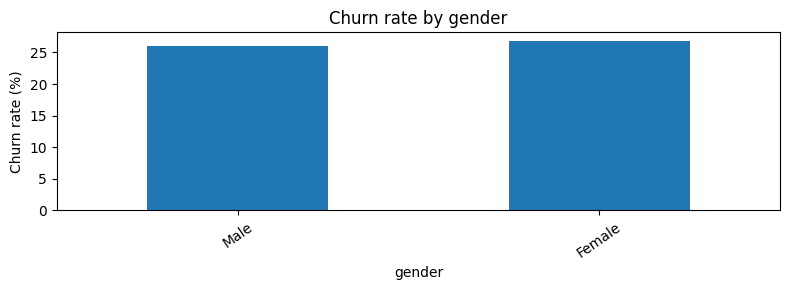

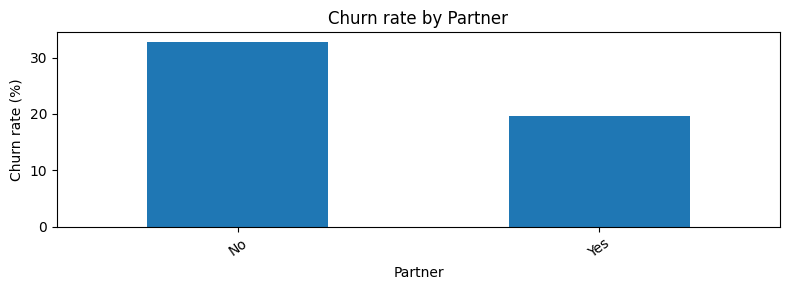

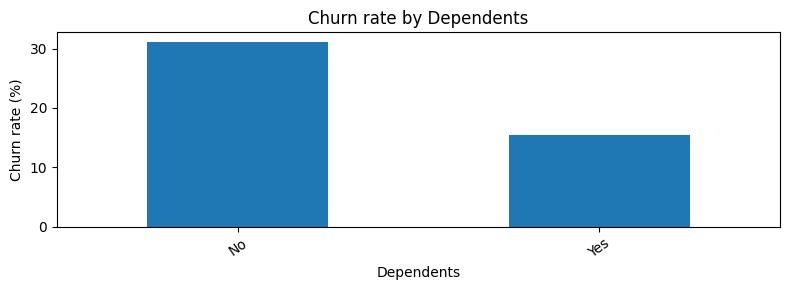

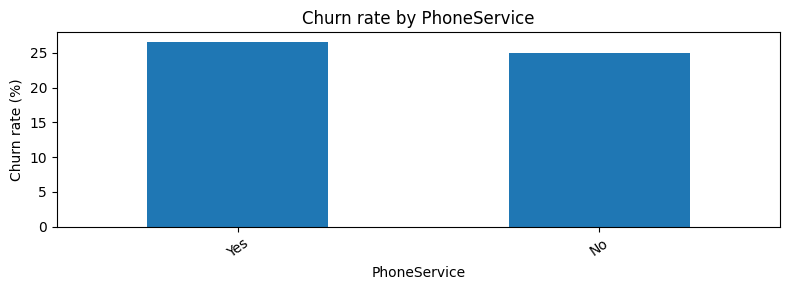

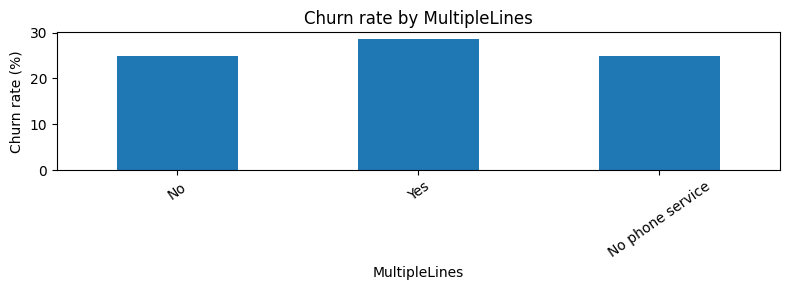

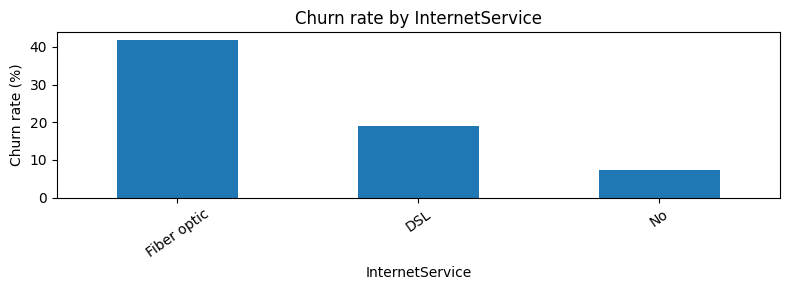

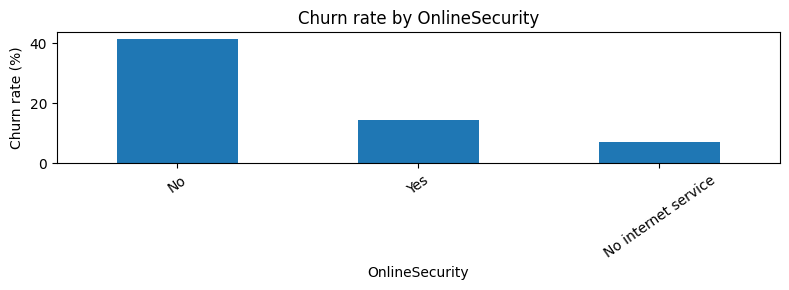

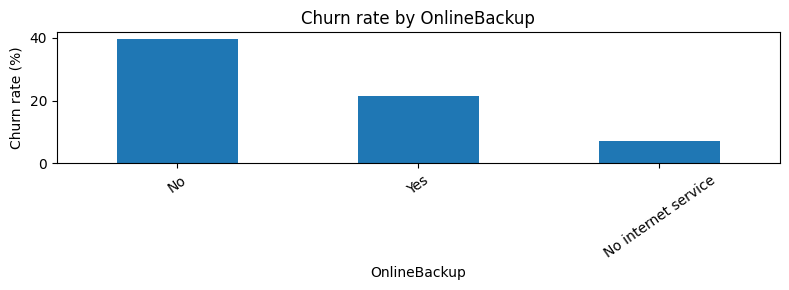

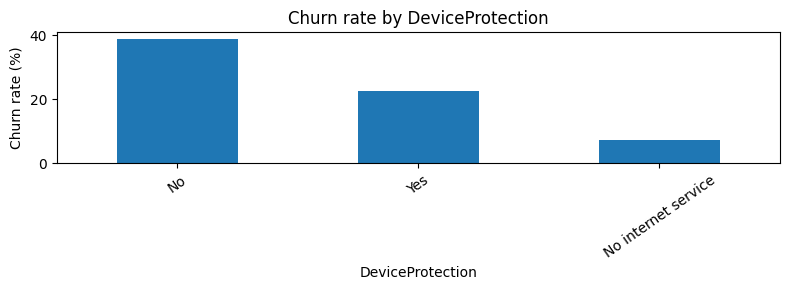

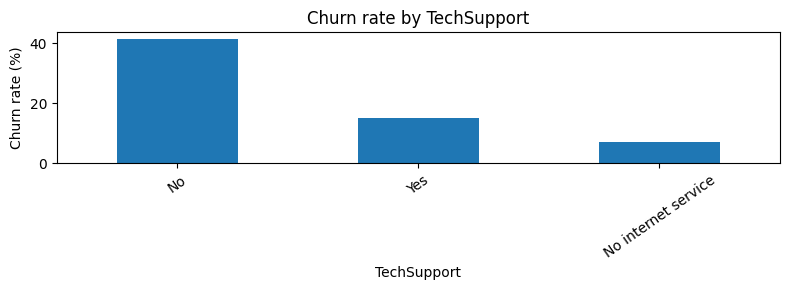

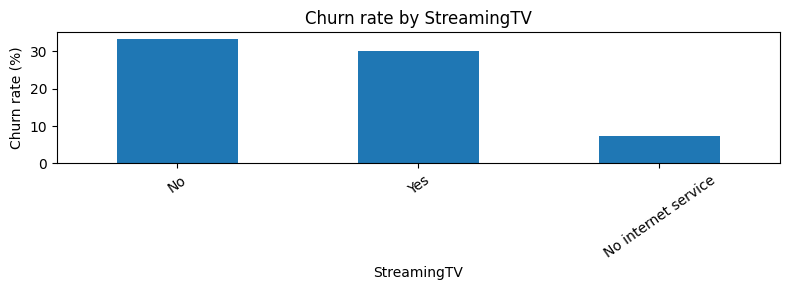

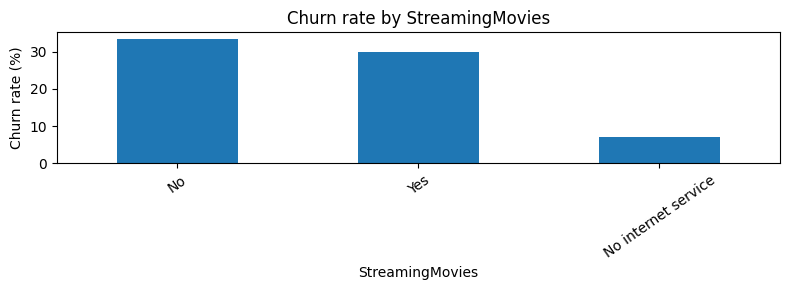

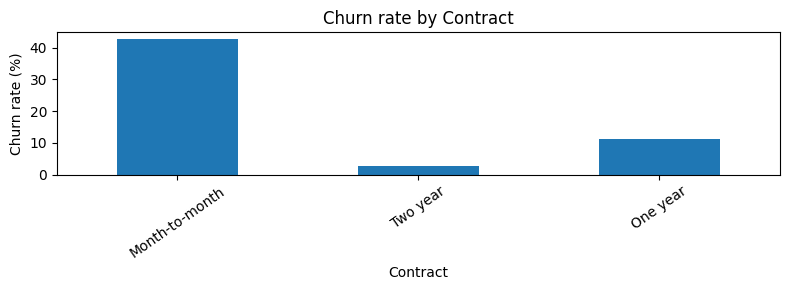

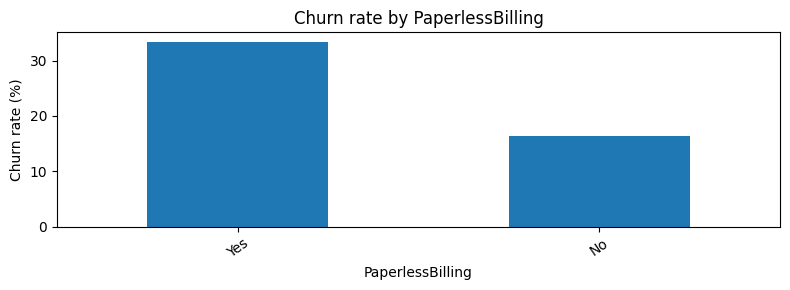

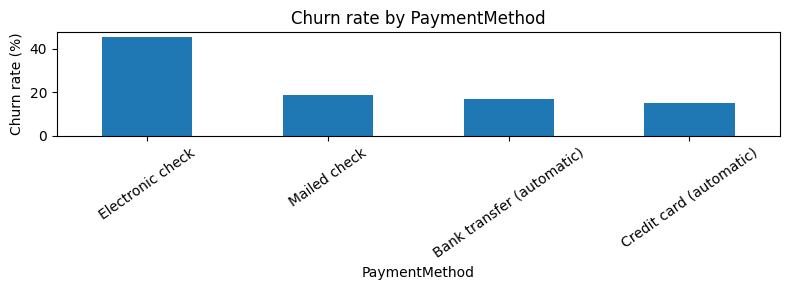

In [13]:
# Churn rate across categorical features (top categories shown for readability)
categorical_cols = df.drop(columns=["Churn"]).select_dtypes(exclude=np.number).columns.tolist()
for col in categorical_cols:
    rates = df.groupby(col, dropna=False)["Churn"].mean().sort_values(ascending=False)
    counts = df[col].value_counts(dropna=False)
    # Keep the plot readable if a column has many categories.
    rates = rates.loc[counts.index[:15]]
    ax = (rates * 100).plot(kind="bar", figsize=(8, 3), rot=35)
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel(col)
    plt.tight_layout()
    plt.show()

### EDA reporting prompts

After inspecting your real outputs, write concise evidence-based observations:
- Is the target balanced or imbalanced? Include the actual class counts and churn percentage.
- Which numeric variables show different averages between churn groups?
- Which contract, service, payment or tenure categories show visibly different churn rates?
- What data quality issue did you find and how was it handled?
- Mention that descriptive patterns are associations, not proof of causation.

## 4. Split features and target

We reserve a stratified test set before tuning. The test set is used only for the final evaluation. All imputing, encoding and scaling are fitted within each training fold by a scikit-learn pipeline to reduce leakage. One-hot encoding handles categorical variables without implying an artificial numeric order.

In [14]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical feature count:", len(categorical_features))
print("Target classes:", sorted(y.unique()))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Training churn rate:", round(y_train.mean(), 4), "| Test churn rate:", round(y_test.mean(), 4))

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical feature count: 15
Target classes: [np.int64(0), np.int64(1)]
Training rows: 5616 | Test rows: 1405
Training churn rate: 0.2644 | Test churn rate: 0.2648


In [15]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

## 5. Train and tune three classifiers

Hyperparameters are tuned using stratified 5-fold cross-validation on the training set. We use F1 as the tuning score to balance precision and recall for the positive (churn) class. Accuracy is also reported, but should not be used alone if the classes are imbalanced. ROC-AUC evaluates ranking across thresholds. For business use, the relative costs of missed churners and unnecessary retention offers should determine the final operating threshold.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

model_specs = {
    "KNN": (
        KNeighborsClassifier(),
        {
            "model__n_neighbors": [5, 9, 15],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]
        }
    ),
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
        {
            "model__C": [0.1, 1.0, 10.0],
            "model__solver": ["liblinear"],
            "model__penalty": ["l1", "l2"]
        }
    ),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
        {
            "model__n_estimators": [100, 250],
            "model__max_depth": [None, 10, 20],
            "model__min_samples_leaf": [1, 3]
        }
    )
}

searches = {}
for name, (estimator, param_grid) in model_specs.items():
    pipe = Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", estimator)
    ])
    search = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True
    )
    search.fit(X_train, y_train)
    searches[name] = search
    print(f"\n{name}")
    print("Best CV F1:", round(search.best_score_, 4))
    print("Best parameters:", search.best_params_)


KNN
Best CV F1: 0.5882
Best parameters: {'model__n_neighbors': 15, 'model__p': 1, 'model__weights': 'uniform'}

Logistic Regression
Best CV F1: 0.6306
Best parameters: {'model__C': 1.0, 'model__penalty': 'l1', 'model__solver': 'liblinear'}

Random Forest
Best CV F1: 0.6364
Best parameters: {'model__max_depth': 10, 'model__min_samples_leaf': 3, 'model__n_estimators': 100}


In [17]:
# Capture the best cross-validation score and best parameters for reporting.
tuning_rows = []
for name, search in searches.items():
    tuning_rows.append({
        "Model": name,
        "Best mean CV F1": search.best_score_,
        "Best parameters": str(search.best_params_)
    })
tuning_results = pd.DataFrame(tuning_rows).sort_values("Best mean CV F1", ascending=False)
display(tuning_results.round(4))
tuning_results.to_csv("tuning_results.csv", index=False)

,Model,Best mean CV F1,Best parameters
2,Random Forest,0.6364,"{'model__max_depth': 10, 'model__min_samples_l..."
1,Logistic Regression,0.6306,"{'model__C': 1.0, 'model__penalty': 'l1', 'mod..."
0,KNN,0.5882,"{'model__n_neighbors': 15, 'model__p': 1, 'mod..."


## 6. Final test-set evaluation

Each selected model is evaluated once on the held-out test set. Precision answers: of customers predicted to churn, what fraction actually churned? Recall answers: of customers who churned, what fraction did the model identify? F1 is the harmonic mean of precision and recall. ROC-AUC measures discrimination using predicted probabilities.

In [18]:
evaluation_rows = []
fitted_models = {}

for name, search in searches.items():
    model = search.best_estimator_
    fitted_models[name] = model
    y_pred = model.predict(X_test)

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, y_score)
    else:
        y_score = None
        auc = np.nan

    evaluation_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": auc
    })
    print(f"\n===== {name} =====")
    print(classification_report(y_test, y_pred, target_names=["No churn", "Churn"], zero_division=0))

results = pd.DataFrame(evaluation_rows).sort_values("F1", ascending=False)
display(results.round(4))
results.to_csv("test_set_results.csv", index=False)


===== KNN =====
              precision    recall  f1-score   support

    No churn       0.84      0.87      0.85      1033
       Churn       0.60      0.52      0.56       372

    accuracy                           0.78      1405
   macro avg       0.72      0.70      0.71      1405
weighted avg       0.77      0.78      0.78      1405


===== Logistic Regression =====
              precision    recall  f1-score   support

    No churn       0.90      0.73      0.80      1033
       Churn       0.51      0.78      0.61       372

    accuracy                           0.74      1405
   macro avg       0.70      0.75      0.71      1405
weighted avg       0.80      0.74      0.75      1405


===== Random Forest =====
              precision    recall  f1-score   support

    No churn       0.88      0.79      0.83      1033
       Churn       0.55      0.71      0.62       372

    accuracy                           0.77      1405
   macro avg       0.72      0.75      0.73      14

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
2,Random Forest,0.7694,0.5500,0.7097,0.6197,0.8403
1,Logistic Regression,0.7409,0.5070,0.7796,0.6144,0.8398
0,KNN,0.7801,0.5969,0.5215,0.5567,0.8183


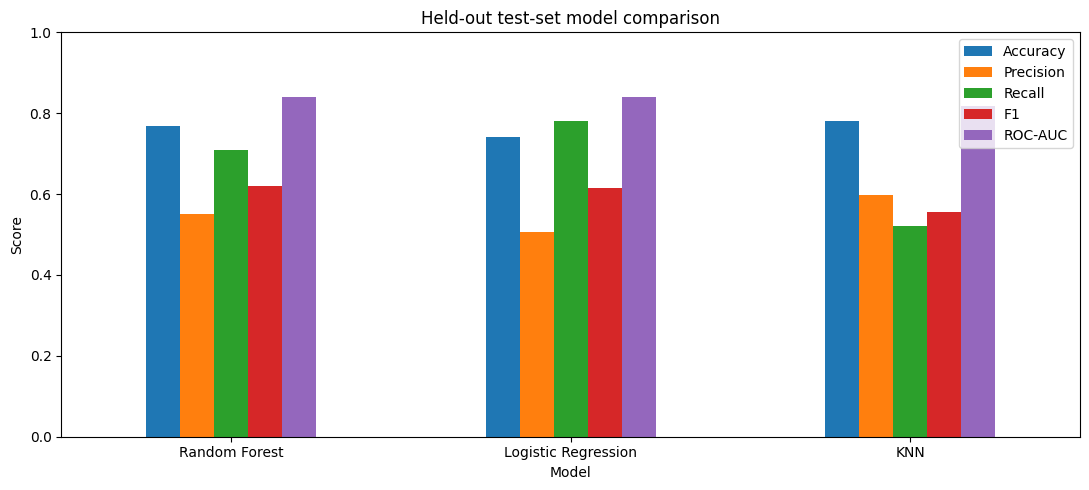

In [19]:
# Plot metric comparison
plot_metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
ax = results.set_index("Model")[plot_metrics].plot(kind="bar", figsize=(11, 5))
ax.set_title("Held-out test-set model comparison")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

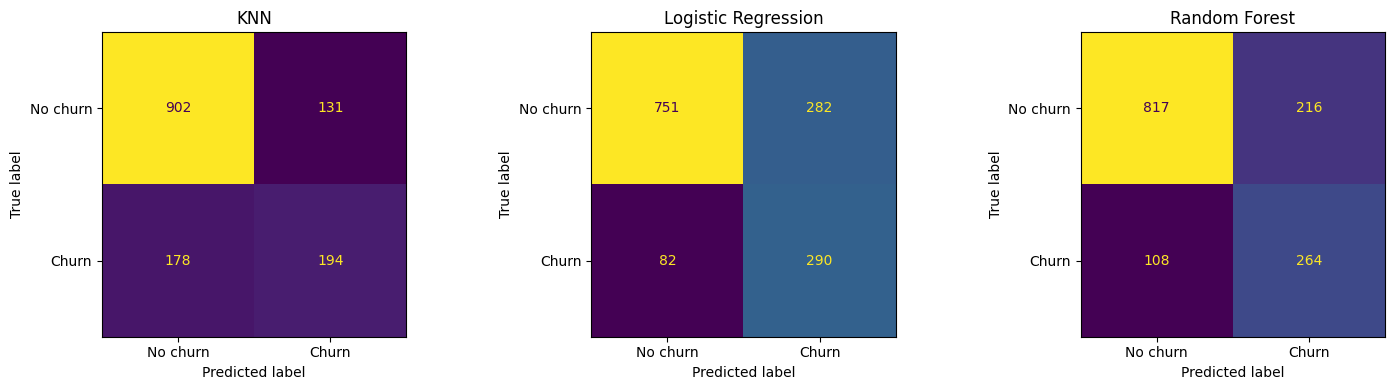

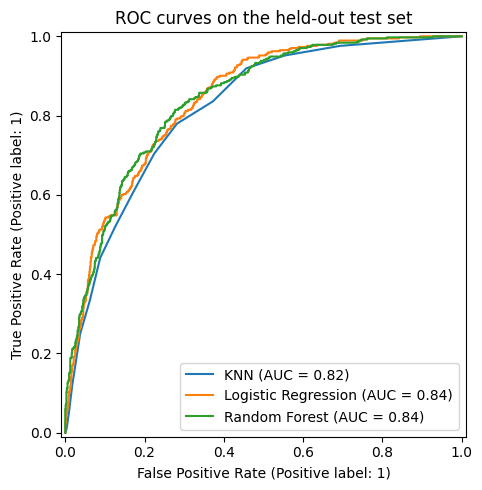

In [20]:
# Confusion matrices and ROC curves
fig, axes = plt.subplots(1, len(fitted_models), figsize=(15, 4))
if len(fitted_models) == 1:
    axes = [axes]
for ax, (name, model) in zip(axes, fitted_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test,
        display_labels=["No churn", "Churn"],
        cmap=None, ax=ax, colorbar=False
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
for name, model in fitted_models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.set_title("ROC curves on the held-out test set")
plt.tight_layout()
plt.show()

## 7. Inspect the selected model

Select the model with the best metric for the stated business objective, not simply the model with the highest accuracy. This cell prints the best model according to test F1 as a convenient starting point. Because test results are used for final comparison, do not repeatedly change model settings based on test performance; any further tuning should be performed within training/CV data.

In [21]:
best_by_f1 = results.iloc[0]["Model"]
print("Highest test-set F1 in this run:", best_by_f1)
print(results.iloc[0].to_dict())

Highest test-set F1 in this run: Random Forest
{'Model': 'Random Forest', 'Accuracy': 0.7693950177935943, 'Precision': 0.55, 'Recall': 0.7096774193548387, 'F1': 0.6197183098591549, 'ROC-AUC': 0.8403348114376126}


## 8. Save reproducibility information

Keep these outputs for the report and Git repository. Do not commit customer-level data unless its license and privacy conditions explicitly allow it. For this public teaching dataset, include the source link and version information in the README.

In [22]:
import sklearn
print("Python/pandas/numpy/scikit-learn versions:")
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("Random state:", RANDOM_STATE)

# Save the cleaned data only if appropriate for the dataset license and your submission rules.
# df.to_csv("cleaned_telco_churn.csv", index=False)
print("Saved result files: tuning_results.csv and test_set_results.csv")

Python/pandas/numpy/scikit-learn versions:
pandas: 2.2.3
numpy: 2.1.3
scikit-learn: 1.6.1
Random state: 42
Saved result files: tuning_results.csv and test_set_results.csv


## 9. Ethics, deployment, limitations and future work — points to discuss

### Ethics during development
- **Data minimisation:** exclude direct customer identifiers from predictors.
- **Privacy and lawful use:** document the dataset source and license; do not expose customer-level records in Git or reports.
- **Fairness:** check performance across relevant customer groups where lawful and ethically justified; do not assume the public dataset contains all protected attributes or that fairness has been proven.
- **Transparency:** document feature processing, hyperparameters, evaluation metrics and limitations.
- **Avoid misleading evaluation:** keep a held-out test set, use stratified splitting, and fit preprocessing only on training folds.
- **Human oversight:** predictions should support, not automatically determine, customer treatment.

### Post-deployment monitoring
- Monitor input data quality, missing values, feature drift, churn prevalence and performance over time.
- Track precision/recall and business outcomes once ground-truth labels become available.
- Reassess group-level error rates, privacy and access controls.
- Set an escalation process for unusual drift or harmful outcomes; retrain only after validation and approval.
- Explain the purpose and limitations of retention actions and provide appropriate human review.

### Limitations and possible enhancements
- A public dataset may be old, geographically limited or not representative of current customers.
- A single random split estimates performance on one sample; repeated cross-validation or external validation would improve confidence.
- F1 and ROC-AUC do not encode the financial cost of false positives and false negatives.
- Hyperparameter grids are limited; broader search may improve results at extra computational cost.
- Further work could include calibrated probabilities, threshold selection using explicit business costs, drift monitoring, subgroup evaluation, and testing on more recent data.

## 10. Final checklist before submission

- [ ] Verify dataset source, license/version and column definitions.
- [ ] Run all cells from top to bottom without errors.
- [ ] Inspect every chart and write only evidence-supported EDA findings.
- [ ] Copy the actual tuning and test-set outputs into your report.
- [ ] Keep the report within 2,000 words (check whether headings and citations count under the brief).
- [ ] Add the publicly accessible Git URL to the report.
- [ ] Include the source code as text in the report appendix, not screenshots.
- [ ] Acknowledge AI use according to the module's guidance.
- [ ] Practise explaining the preprocessing, each model, the metrics, ethics and limitations for the compulsory viva.